# 01. Làm sạch dữ liệu

**Mục tiêu:** biến telemetry thô thành bảng mỗi dòng một chuyến bay, có cột năng lượng, và ghi lại mọi chuyến bị loại kèm lý do.

**Đầu vào:** `data/raw/parameters.csv`, `data/raw/flights.csv`

**Đầu ra:** `data/processed/flight_level.csv`, `reports/exclusion_log.csv`

## 0. Chuẩn bị

In [256]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Gốc repo: chạy notebook từ thư mục notebooks/ hay từ gốc đều được
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "reports" / "figures"
SEED = 301

## 1. Đọc dữ liệu

- [x] Mỗi file có bao nhiêu dòng, bao nhiêu cột?
  - `parameters.csv`: 209 dòng × 7 cột, mỗi dòng là một chuyến bay (cài đặt trước khi bay).
  - `flights.csv`: 257.896 dòng × 28 cột, mỗi dòng là một lần ghi telemetry trong lúc bay.
- [x] Cột nào là thời gian, điện áp, dòng điện? Đơn vị gì?
  - Nằm trong `flights.csv`: `time` (giây), `battery_voltage` (V), `battery_current` (A).
- [x] Đơn vị các cột của `parameters.csv` (theo README của dataset, kiểm bằng độ hợp lý):
  - `speed`: m/s. Giá trị 4–12 m/s = 14–43 km/h, hợp lý cho drone. Nếu là km/h thì 4 km/h còn chậm hơn người đi bộ.
  - `payload`: gram. 0, 250, 500 g = cỡ hộp thuốc nhỏ. Nếu là kg thì 500 kg, drone không chở nổi.
  - `altitude`: mét. 25–100 m là độ cao bay drone bình thường.
  - `date`, `local_time`: ngày và giờ địa phương (Pittsburgh, Mỹ).
  - `route`: không có đơn vị, chỉ là tên tuyến bay.
- [x] Hai file nối với nhau bằng cột nào?
  - Cột `flight` (mã chuyến). Cả 2 file đều có đúng 209 mã chuyến giống nhau (xem ô kiểm tra bên dưới).

In [257]:
params = pd.read_csv(RAW / "parameters.csv")
params.shape

(209, 7)

In [258]:
params.head()

,flight,speed,payload,altitude,date,local_time,route
0,1,4.0,0.0,25,2019-04-07,10:13,R5
1,2,4.0,0.0,50,2019-04-07,10:23,R5
2,3,6.0,0.0,25,2019-04-07,10:33,R5
3,4,8.0,0.0,25,2019-04-07,10:48,R5
4,5,4.0,0.0,25,2019-04-07,11:05,R2


In [259]:
flights = pd.read_csv(RAW / "flights.csv", low_memory=False)
flights.shape

(257896, 28)

In [260]:
flights.head()

,flight,time,wind_speed,wind_angle,battery_voltage,battery_current,position_x,position_y,position_z,orientation_x,...,angular_z,linear_acceleration_x,linear_acceleration_y,linear_acceleration_z,speed,payload,altitude,date,time_day,route
0,1,0.0,0.1,12.0,24.222174,0.087470,-79.782396,40.458047,269.332402,0.001772,...,0.006815,0.004258,-0.120405,-9.811137,4.0,0.0,25,2019-04-07,10:13,R5
1,1,0.2,0.1,3.0,24.227180,0.095421,-79.782396,40.458047,269.332056,0.001768,...,0.002034,0.006175,-0.116397,-9.810392,4.0,0.0,25,2019-04-07,10:13,R5
2,1,0.3,0.1,352.0,24.225929,0.095421,-79.782396,40.458047,269.333081,0.001768,...,-0.000874,0.002696,-0.128592,-9.809440,4.0,0.0,25,2019-04-07,10:13,R5
3,1,0.5,0.1,354.0,24.224678,0.095421,-79.782396,40.458047,269.334648,0.001775,...,0.002443,0.002024,-0.128271,-9.810159,4.0,0.0,25,2019-04-07,10:13,R5
4,1,0.6,0.1,359.0,24.210905,0.079518,-79.782396,40.458047,269.336178,0.001775,...,-0.006425,0.008271,-0.119890,-9.812125,4.0,0.0,25,2019-04-07,10:13,R5


### Khoảng thời gian giữa 2 lần ghi

- `.groupby("flight")`: chia bảng theo từng chuyến, để không trừ lẫn dòng cuối chuyến này với dòng đầu chuyến sau.
- `.diff()`: lấy mỗi dòng trừ dòng trước, tức là khoảng cách giữa 2 lần ghi.
- `.describe()`: tóm tắt các khoảng đó (trung bình, nhỏ nhất, lớn nhất).

In [261]:
# Khoảng cách giữa 2 lần ghi, tính riêng trong từng chuyến
flights.groupby("flight")["time"].diff().describe()

count    257687.000000
mean          0.150250
std           0.053285
min           0.060000
25%           0.100000
50%           0.120000
75%           0.200000
max           5.280000
Name: time, dtype: float64

**Kết luận:** count = 257.687 = 257.896 dòng − 209 chuyến (mỗi chuyến mất 1 dòng đầu), đúng như mong đợi. Khoảng ghi trung bình 0,15 s nhưng dao động từ 0,06 s đến 5,28 s, tức là ghi **không đều**. Vì vậy khi tính năng lượng phải dùng Δt thật của từng đoạn, không dùng một Δt cố định.

### Kiểm tra cột nối hai file

In [262]:
# Hai file có cùng danh sách mã chuyến không?
print(params["flight"].nunique(), flights["flight"].nunique())
print(set(params["flight"]) == set(flights["flight"]))

209 209
True


**Kết luận:** hai file nối với nhau bằng cột `flight`. Cả 2 đều có 209 mã chuyến và danh sách giống hệt nhau, không chuyến nào chỉ có ở một file.

## 2. Kiểm tra chất lượng

Mỗi bước kiểm xuất phát từ công thức năng lượng **E = Σ V × I × Δt**: em liệt kê những gì có thể làm E tính sai, rồi kiểm từng cái.

| Cái gì làm sai E? | Bước kiểm |
|---|---|
| Thiếu V hoặc I thì không nhân được | Ô trống (`isna`) |
| Một dòng xuất hiện 2 lần thì bị cộng 2 lần | Dòng trùng (`duplicated`) |
| Δt không đều hoặc bị ngắt thì cộng sai | Khoảng ghi (`dt`) |
| V hoặc I có số vô lý thì kết quả vô lý | Khoảng giá trị (`describe`) |
| Tốc độ, tải, độ cao phải là số mới đưa vào mô hình được | Kiểu dữ liệu (`dtypes`) |

- [x] Có giá trị thiếu không? Ở cột nào? → Không có ô trống ở cả 2 file.
- [x] Có dòng trùng không? Mốc thời gian trùng không? → Không có dòng trùng. Không có mốc thời gian trùng trong cùng một chuyến, vì khoảng ghi nhỏ nhất là 0,06 s > 0 (mục 1).
- [x] Có giá trị sai kiểu không? → Có: `altitude` bị lưu dạng chữ (xem 2.2).
- [x] Khoảng cách thời gian giữa hai mẫu có đều không? → Không đều, có 10 chỗ bị ngắt trên 1 giây (xem 2.3).

### 2.1 Ô trống và dòng trùng

In [263]:
# Ô trống
print("Ô trống params:", params.isna().sum().sum())
print("Ô trống flights:", flights.isna().sum().sum())
# Dòng trùng (2 dòng giống hệt nhau)
print("Dòng trùng params:", params.duplicated().sum())
print("Dòng trùng flights:", flights.duplicated().sum())

Ô trống params: 0
Ô trống flights: 0
Dòng trùng params: 0
Dòng trùng flights: 0


**Kết luận:** không có ô trống, không có dòng trùng ở cả 2 file, nên không cần xử lý.

### 2.2 Kiểu dữ liệu

In [264]:
params.dtypes

flight          int64
speed         float64
payload       float64
altitude          str
date              str
local_time        str
route             str
dtype: object

In [265]:
params["altitude"].unique()

<StringArray>
['25', '50', '75', '100', '0', '3', '25-50-100-25']
Length: 7, dtype: str

In [266]:
params["speed"].unique()

array([ 4.,  6.,  8., 10., 12.,  0.])

In [267]:
params["payload"].unique()

array([  0., 250., 750., 500.])

**Kết luận:** `flight`, `speed`, `payload` là số, đúng như mong đợi. Nhưng `altitude` bị lưu dạng **chữ**, vì có giá trị `'25-50-100-25'` (chuyến đổi độ cao giữa chừng). Ngoài ra có độ cao 0 m và 3 m, không phải độ cao bay giao hàng. Hai nhóm này xử lý ở mục 3; sau khi lọc sẽ đổi `altitude` về dạng số.

### 2.3 Khoảng ghi bị ngắt

Chọn mốc 1 giây vì bình thường máy ghi khoảng 0,15 s một lần, 1 s là dài gấp khoảng 7 lần, chắc chắn là bất thường.

In [268]:
# Thêm cột dt = khoảng cách giữa 2 lần ghi, tính trong từng chuyến
flights["dt"] = flights.groupby("flight")["time"].diff()

# Lọc ra những chỗ dt lớn hơn 1 giây
flights[flights["dt"] > 1][["flight", "time", "dt"]]

,flight,time,dt
58934,108,147.40,1.40
60113,109,162.50,1.10
61825,110,167.00,1.70
65775,113,178.00,1.80
96902,140,177.80,1.10
246000,268,228.52,1.12
247064,269,158.70,2.10
254936,277,13.90,1.30
256616,278,142.39,5.28
256967,279,13.40,4.70


Câu hỏi tiếp theo: đoạn bị ngắt chiếm bao nhiêu % thời gian bay của chuyến đó?

In [269]:
# Thời gian bay của từng chuyến = time lớn nhất - time nhỏ nhất
thoi_gian_bay = flights.groupby("flight")["time"].agg(lambda t: t.max() - t.min())

# Tổng thời gian bị mất (dt > 1 s) của từng chuyến
mat_tin_hieu = flights[flights["dt"] > 1].groupby("flight")["dt"].sum()

# Phần trăm thời gian bị mất
(mat_tin_hieu / thoi_gian_bay.loc[mat_tin_hieu.index] * 100).round(2)

flight
108    0.86
109    0.43
110    0.69
113    0.89
140    0.55
268    0.48
269    1.04
277    0.96
278    2.83
279    3.08
dtype: float64

**Kết luận:** có 10 chỗ bị ngắt trên 1 giây, ở 10 chuyến khác nhau. Mỗi chuyến chỉ mất dưới khoảng 1% thời gian bay; riêng chuyến 278 và 279 mất khoảng 3%, hai chuyến này là route R7 và sẽ bị loại ở mục 3. Đoạn bị ngắt quá nhỏ so với cả chuyến, ảnh hưởng tới năng lượng không đáng kể, nên em **giữ lại** các chuyến này.

### 2.4 Điện áp và dòng điện có giá trị vô lý không?

In [270]:
flights[["battery_voltage", "battery_current"]].describe().round(2)

,battery_voltage,battery_current
count,257896.00,257896.00
mean,22.44,17.93
std,1.20,10.87
min,18.81,-0.33
25%,21.51,7.14
50%,22.31,21.92
75%,23.16,25.27
max,25.89,47.19


Dòng điện có giá trị âm (min −0,33 A). Xem kỹ các dòng âm:

In [271]:
am = flights[flights["battery_current"] < 0]
print("Số dòng âm:", len(am))
am["battery_current"].describe().round(2)

Số dòng âm: 29031


count    29031.00
mean        -0.06
std          0.05
min         -0.33
25%         -0.10
50%         -0.05
75%         -0.02
max         -0.01
Name: battery_current, dtype: float64

**Kết luận:**
- Điện áp từ 18,8 V đến 25,9 V, hợp lý với pin 6 cell (sạc đầy khoảng 25 V, giảm dần khi bay).
- Dòng điện âm rất nhỏ (trung bình −0,06 A), xuất hiện chủ yếu lúc drone nằm dưới đất, motor tắt. Đó là nhiễu cảm biến quanh mức 0, không phải pin được sạc. Ảnh hưởng khoảng 1 W so với khoảng 400 W lúc bay, nên em **giữ nguyên**.

## 3. Đặt luật lọc

**Nguyên tắc:** luật lọc không đặt theo cảm tính, mà tách ra từ câu hỏi nghiên cứu: *"Dự đoán **năng lượng** của một **chuyến bay giao hàng** từ **tốc độ, tải và độ cao**."* Mỗi chuyến phải qua 3 cửa:

| Cụm trong câu hỏi | Đòi hỏi gì ở mỗi chuyến | Cửa |
|---|---|---|
| "chuyến bay giao hàng" | Phải đúng là bay giao hàng | 1 |
| "năng lượng" | Năng lượng phải đo đúng (cảm biến hoạt động) | 2 |
| "từ tốc độ, tải, độ cao" | Tả được bằng 3 con số đó, nằm trong phạm vi thí nghiệm | 3 |

Thứ tự làm: đặt luật từ câu hỏi **trước**, rồi mới dùng dữ liệu tìm chuyến trượt, và kiểm lại từng chuyến bằng bằng chứng. Mỗi chuyến bị loại được ghi vào sổ `so_loai`: số chuyến, luật nào, bằng chứng gì.

- [x] Đếm giá trị từng cột tham số. Cái gì nằm ngoài lưới thiết kế? → mục 3.0
- [x] Mỗi luật lọc dựa trên lý do gì, gắn với câu hỏi nghiên cứu thế nào? → bảng 3 cửa ở trên, chi tiết ở 3.1 đến 3.4 (4 luật)
- [x] Kiểm từng chuyến bị loại bằng data: lý do có đúng không? → mỗi luật có ô "bằng chứng" 

### 3.0 Tìm nghi phạm: giá trị nào nằm ngoài lưới thiết kế?

Lưới thiết kế của thí nghiệm (đề bài mục 4.1 và bài báo gốc): tốc độ 4, 6, 8, 10, 12 m/s; tải 0, 250, 500 g; độ cao 25, 50, 75, 100 m. Đếm từng cột để xem giá trị nào nằm ngoài lưới.

In [272]:
params["route"].value_counts()

route
R1    182
R6      5
R5      4
H       4
A1      3
A2      3
A3      3
R7      2
R2      1
R3      1
R4      1
Name: count, dtype: int64

In [273]:
for cot in ["speed", "payload", "altitude"]:
    print(params[cot].value_counts().sort_index(), "\n")

speed
0.0     13
4.0     41
6.0     38
8.0     36
10.0    43
12.0    38
Name: count, dtype: int64 

payload
0.0      80
250.0    62
500.0    66
750.0     1
Name: count, dtype: int64 

altitude
0                9
100             45
25              54
25-50-100-25     2
3                4
50              48
75              47
Name: count, dtype: int64 



In [274]:
# Lưới thiết kế: các giá trị hợp lệ của từng feature
# (altitude lúc này còn dạng chữ nên ghi trong ngoặc kép)
luoi = {"speed": [4, 6, 8, 10, 12],
        "payload": [0, 250, 500],
        "altitude": ["25", "50", "75", "100"]}

for cot, hop_le in luoi.items():
    ngoai = params[~params[cot].isin(hop_le)]      # các chuyến có giá trị KHÔNG nằm trong lưới
    print(cot, "| ngoài lưới:", ngoai[cot].value_counts().to_dict(),
          "| thuộc route:", sorted(ngoai["route"].unique()))

speed | ngoài lưới: {0.0: 13} | thuộc route: ['A1', 'A2', 'A3', 'H']
payload | ngoài lưới: {750.0: 1} | thuộc route: ['R1']
altitude | ngoài lưới: {'0': 9, '3': 4, '25-50-100-25': 2} | thuộc route: ['A1', 'A2', 'A3', 'H', 'R7']


**Kết luận:** route R1 chiếm 182/209 chuyến. Các giá trị nằm ngoài lưới thiết kế:
- `speed = 0`: 13 chuyến (route A1, A2, A3, H)
- `payload = 750`: 1 chuyến
- `altitude = 0`, `3`, `'25-50-100-25'`: 9, 4, 2 chuyến

Đây là các nghi phạm. Mỗi nhóm được xét ở một luật bên dưới.

### 3.1 Luật 1: không phải chuyến bay giao hàng (cửa 1)

Xem các chuyến có route không bắt đầu bằng chữ R

In [275]:
params[~params["route"].str.startswith("R")]

,flight,speed,payload,altitude,date,local_time,route
148,211,0.0,0.0,0,2019-07-18,9:20,A1
149,212,0.0,0.0,0,2019-07-18,9:25,A1
150,213,0.0,0.0,0,2019-07-18,9:30,A1
151,214,0.0,0.0,0,2019-07-18,9:36,A2
152,215,0.0,0.0,0,2019-07-18,9:42,A2
153,216,0.0,0.0,0,2019-07-18,9:49,A2
154,217,0.0,0.0,0,2019-07-18,9:52,A3
155,218,0.0,0.0,0,2019-07-18,10:01,A3
156,219,0.0,0.0,0,2019-07-18,10:04,A3
157,221,0.0,0.0,3,2019-07-18,14:22,H


Các chuyến độ cao 0 m và 3 m có trùng với nhóm speed = 0 không? Dùng bảng chéo để kiểm:

In [276]:
pd.crosstab(params["altitude"], params["speed"] == 0)

speed,False,True
altitude,,
0,0,9
100,45,0
25,54,0
25-50-100-25,2,0
3,0,4
50,48,0
75,47,0


In [277]:
# Sổ ghi các chuyến bị loại
so_loai = []

# Luật 1: không phải bay giao hàng (tốc độ = 0)
luat1 = params[params["speed"] == 0]
for f in luat1["flight"]:
    so_loai.append({"flight": f, "luat": "1. Không phải bay giao hàng",
                    "bang_chung": "speed = 0 (route A1–A3/H)"})

print("Luật 1 loại:", len(luat1), "chuyến")

Luật 1 loại: 13 chuyến


**Kết luận:** 13 chuyến có `speed = 0`, độ cao 0 m (A1–A3, nằm yên dưới đất) hoặc 3 m (H = hover, bay lơ lửng tại chỗ). Drone không di chuyển đi đâu nên đây là các lần đo thử, **không phải bay giao hàng** → loại. Bảng chéo cho thấy các chuyến độ cao 0 và 3 m đều nằm trong nhóm này, nên không cần luật riêng cho chúng.

Lọc theo `speed == 0` thay vì theo tên route, vì lý do thật là "không di chuyển"; tên A1, H chỉ là nhãn. Hai cách cho cùng 13 chuyến.

### 3.2 Luật 2: đổi độ cao giữa chừng (cửa 3)

In [278]:
params[params["altitude"].str.contains("-")]

,flight,speed,payload,altitude,date,local_time,route
207,278,10.0,500.0,25-50-100-25,2019-10-24,10:00,R7
208,279,10.0,0.0,25-50-100-25,2019-10-24,10:10,R7


Bằng chứng từ hộp đen: `position_z` là độ cao so với mực nước biển (mặt đất ở đó khoảng 268 m), nên lấy cao nhất trừ thấp nhất để ra độ cao đã leo. So với chuyến 1 (cài đặt 25 m):

In [279]:
# Drone leo cao bao nhiêu so với lúc cất cánh?
# position_z là độ cao đo bằng GPS, tính từ mực nước biển
for f in [1, 278, 279]:
    z = flights[flights["flight"] == f]["position_z"]
    thap_nhat = z.min()   # lúc nằm dưới đất
    cao_nhat = z.max()    # lúc bay cao nhất
    print("Chuyến", f,
          "| thấp nhất:", round(thap_nhat, 1), "m",
          "| cao nhất:", round(cao_nhat, 1), "m",
          "| leo cao:", round(cao_nhat - thap_nhat, 1), "m")

Chuyến 1 | thấp nhất: 268.1 m | cao nhất: 295.6 m | leo cao: 27.4 m
Chuyến 278 | thấp nhất: 269.4 m | cao nhất: 365.5 m | leo cao: 96.1 m
Chuyến 279 | thấp nhất: 270.0 m | cao nhất: 365.9 m | leo cao: 95.9 m


In [280]:
# Luật 2: đổi độ cao giữa chừng, không tả được bằng một con số độ cao
luat2 = params[params["altitude"].str.contains("-")]
for f in luat2["flight"]:
    so_loai.append({"flight": f, "luat": "2. Đổi độ cao giữa chừng",
                    "bang_chung": "altitude = 25-50-100-25 (route R7)"})
print("Luật 2 loại:", len(luat2), "chuyến")

Luật 2 loại: 2 chuyến


**Kết luận:** chuyến 278 và 279 (route R7) có độ cao ghi là `25-50-100-25`. Hộp đen xác nhận: chuyến 1 (cài 25 m) chỉ leo khoảng 27,4 m, còn 278 và 279 leo khoảng 96 m rồi hạ xuống. Mô hình nhận **một** con số độ cao cho mỗi chuyến, mà hai chuyến này bay qua nhiều độ cao, không có con số nào đúng để đưa vào → loại.

### 3.3 Luật 3: tải nằm ngoài phạm vi thí nghiệm (cửa 3)

In [281]:
params[params["payload"] > 500]

,flight,speed,payload,altitude,date,local_time,route
20,76,4.0,750.0,25,2019-06-11,9:36,R1


In [282]:
# Luật 3: tải 750 g, ngoài lưới thiết kế (0, 250, 500 g) và chỉ có 1 chuyến
luat3 = params[params["payload"] > 500]
for f in luat3["flight"]:
    so_loai.append({"flight": f, "luat": "3. Tải ngoài phạm vi thí nghiệm",
                    "bang_chung": "payload = 750 g, chỉ có 1 chuyến"})
print("Luật 3 loại:", len(luat3), "chuyến")

Luật 3 loại: 1 chuyến


**Kết luận:** chuyến 76 chở 750 g, trong khi lưới thiết kế chỉ có 0, 250, 500 g, và cả bộ dữ liệu chỉ có đúng 1 chuyến ở mức này. Câu hỏi nghiên cứu xét trong phạm vi tải của thí nghiệm. Một chuyến lẻ không đủ để mô hình học được mức 750 g, và đánh giá mô hình trên nó là ngoại suy ra ngoài phạm vi → loại.

### 3.4 Luật 4: chuyến 196 ghi dư sau khi hạ cánh (cửa 2)

Để năng lượng đo đúng và so sánh được giữa các chuyến, mọi chuyến phải được ghi **cùng một cách**: README của dataset định nghĩa *"một chuyến là dữ liệu ghi từ lúc cất cánh tới lúc hạ cánh"*. Đồng thời phải kiểm cảm biến dòng điện có hoạt động không (nếu luôn đọc gần 0 A thì năng lượng sai). Lúc bay, dòng điện khoảng 20–40 A, nên một chuyến có **trung vị** dòng điện gần 0 là đáng nghi. Xem 5 chuyến có trung vị thấp nhất (trong các chuyến chưa bị loại):

In [283]:
da_loai = [dong["flight"] for dong in so_loai]
trung_vi = flights.groupby("flight")["battery_current"].median()
trung_vi = trung_vi.drop(da_loai)
trung_vi.sort_values().head(5).round(1)

flight
196     0.0
146    16.5
141    17.4
85     18.2
79     18.6
Name: battery_current, dtype: float64

Chuyến 196 có trung vị 0 A, khác hẳn các chuyến còn lại (thấp nhất kế tiếp là 16,5 A). Nhưng trung vị bằng 0 chỉ có nghĩa là **hơn một nửa số dòng** gần 0 A. Phải xem dòng điện thay đổi thế nào theo thời gian trước khi kết luận cảm biến hỏng:

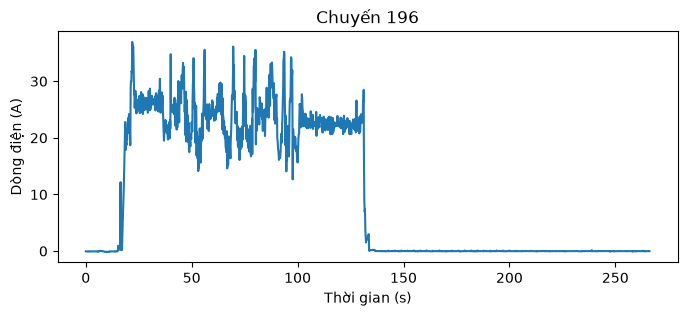

In [284]:
f196 = flights[flights["flight"] == 196]
plt.figure(figsize=(8, 3))
plt.plot(f196["time"], f196["battery_current"])
plt.xlabel("Thời gian (s)")
plt.ylabel("Dòng điện (A)")
plt.title("Chuyến 196")
plt.show()

So với 2 chuyến khác có **cùng cài đặt** (12 m/s, 250 g, 50 m): xét những lúc motor đang chạy (dòng điện > 1 A), chuyến 196 chạy bao lâu và dòng điện trung bình bao nhiêu?

In [285]:
cung_cai_dat = params[(params["speed"] == 12) & (params["payload"] == 250) & (params["altitude"] == "50")]
for f in cung_cai_dat["flight"]:
    g = flights[flights["flight"] == f]
    dang_bay = g[g["battery_current"] > 1]
    print("Chuyến", f,
          "| ghi tổng", round(g["time"].max() - g["time"].min()), "s",
          "| motor chạy", round(dang_bay["dt"].sum()), "s",
          "| dòng TB khi chạy", round(dang_bay["battery_current"].mean(), 1), "A")

Chuyến 23 | ghi tổng 127 s | motor chạy 117 s | dòng TB khi chạy 24.4 A
Chuyến 151 | ghi tổng 150 s | motor chạy 117 s | dòng TB khi chạy 24.6 A
Chuyến 196 | ghi tổng 266 s | motor chạy 117 s | dòng TB khi chạy 23.2 A


In [286]:
# Luật 4: ghi dư sau khi hạ cánh, không khớp định nghĩa chuyến bay của README
so_loai.append({"flight": 196, "luat": "4. Ghi dư sau hạ cánh",
                "bang_chung": "khoảng 2 phút dòng điện ≈ 0 A sau khi hạ cánh"})
print("Luật 4 loại: 1 chuyến")

Luật 4 loại: 1 chuyến


**Kết luận:** chuyến 196 có trung vị dòng điện 0 A, nhưng **cảm biến không hỏng**. Biểu đồ cho thấy khoảng 120 giây đầu dòng điện 20–35 A như một chuyến bay bình thường; thời gian motor chạy (117 s) và dòng điện trung bình (khoảng 23 A) tương đương 2 chuyến cùng cài đặt (23 và 151). Sau đó dòng điện về 0 A vì drone đã hạ cánh, nhưng máy **vẫn tiếp tục ghi khoảng 2 phút**, nên hơn nửa số dòng là 0 A và kéo trung vị về 0.

Như vậy chuyến 196 không khớp định nghĩa "từ cất cánh tới hạ cánh" của README: nó được ghi khác cách với mọi chuyến còn lại → **loại** để đảm bảo mọi chuyến được ghi cùng một cách.

Lưu ý khi trình bày: lý do loại là **ghi dư sau hạ cánh**, không phải "cảm biến hỏng", vì bằng chứng ở trên cho thấy cảm biến vẫn đo bình thường. Năng lượng của chuyến này (khoảng 16,9 Wh) vẫn hợp lý, nên việc loại hay giữ ảnh hưởng rất nhỏ tới kết quả; nhóm chọn loại để thống nhất với bộ 192 chuyến đã dùng để huấn luyện mô hình.

### 3.5 Tổng kết: sổ loại và bảng giữ lại

In [287]:
so_loai = pd.DataFrame(so_loai)
print("Tổng số chuyến bị loại:", len(so_loai))
so_loai["luat"].value_counts()

Tổng số chuyến bị loại: 17


luat
1. Không phải bay giao hàng        13
2. Đổi độ cao giữa chừng            2
3. Tải ngoài phạm vi thí nghiệm     1
4. Ghi dư sau hạ cánh               1
Name: count, dtype: int64

In [288]:
so_loai

,flight,luat,bang_chung
0,211,1. Không phải bay giao hàng,speed = 0 (route A1–A3/H)
1,212,1. Không phải bay giao hàng,speed = 0 (route A1–A3/H)
2,213,1. Không phải bay giao hàng,speed = 0 (route A1–A3/H)
3,214,1. Không phải bay giao hàng,speed = 0 (route A1–A3/H)
4,215,1. Không phải bay giao hàng,speed = 0 (route A1–A3/H)
5,216,1. Không phải bay giao hàng,speed = 0 (route A1–A3/H)
6,217,1. Không phải bay giao hàng,speed = 0 (route A1–A3/H)
7,218,1. Không phải bay giao hàng,speed = 0 (route A1–A3/H)
8,219,1. Không phải bay giao hàng,speed = 0 (route A1–A3/H)
9,221,1. Không phải bay giao hàng,speed = 0 (route A1–A3/H)


In [289]:
# Giữ lại các chuyến không có trong sổ loại
giu = params[~params["flight"].isin(so_loai["flight"])].copy()

# Sau khi loại '25-50-100-25', 0 và 3, cột altitude chỉ còn số -> đổi về kiểu số
giu["altitude"] = giu["altitude"].astype(int)

print("Còn lại:", len(giu), "chuyến")
print("Kiểm tra:", len(giu), "+", len(so_loai), "=", len(giu) + len(so_loai))
for cot in ["speed", "payload", "altitude"]:
    print(cot, sorted(giu[cot].unique().tolist()))

Còn lại: 192 chuyến
Kiểm tra: 192 + 17 = 209
speed [4.0, 6.0, 8.0, 10.0, 12.0]
payload [0.0, 250.0, 500.0]
altitude [25, 50, 75, 100]


**Kết luận mục 3:** từ 209 chuyến, loại 17 chuyến theo 4 luật, còn **192 chuyến**:

| Luật | Cửa | Số chuyến | Chuyến |
|---|---|---|---|
| 1. Không phải bay giao hàng (speed = 0) | 1 | 13 | 211–219, 221–224 |
| 2. Đổi độ cao giữa chừng | 3 | 2 | 278, 279 |
| 3. Tải ngoài phạm vi (750 g) | 3 | 1 | 76 |
| 4. Ghi dư sau hạ cánh | 2 | 1 | 196 |

Sau khi lọc, tốc độ, tải, độ cao đều nằm trong lưới thiết kế, và `altitude` đã là số.

**Điểm còn mở:** ngoài R1 vẫn còn một số chuyến bay route khác (R2–R6). README cho biết các route này khác R1 ở điểm xuất phát. Route không phải biến đầu vào của mô hình, nên được kiểm ở mục 4.5 (sau khi có năng lượng).

## 4. Tính năng lượng từng chuyến

Năng lượng là **biến mục tiêu** (cái mô hình sẽ dự đoán), nên phải tính đúng và kiểm được.

**Công thức:**
- Công suất tại mỗi thời điểm: **P = V × I** (oát, W = J/s). V là điện áp (V), I là dòng điện (A).
- Năng lượng cả chuyến: cộng dồn công suất theo thời gian, **E = Σ P × Δt** (jun, J).
- Vì máy ghi không đều (mục 2.3), mỗi đoạn dùng **Δt thật** giữa 2 lần ghi, không dùng một Δt cố định.
- Trong một đoạn, công suất ở đầu và cuối đoạn khác nhau một chút, nên lấy **trung bình 2 đầu**: E_đoạn = (P_trước + P_sau) / 2 × Δt. Cách này gọi là **quy tắc hình thang**.
- Đổi đơn vị: 1 Wh = 1 W chạy trong 1 giờ = 3600 J, nên **Wh = J / 3600**. Dùng Wh vì đó là đơn vị quen thuộc của pin (pin drone này 4500 mAh × 22,2 V ≈ 100 Wh).

- [x] Công suất = ? Năng lượng = ? → P = V × I; E = Σ (P_trước + P_sau)/2 × Δt
- [x] Tính tay một đoạn, so với code → mục 4.1
- [x] Đổi J sang Wh thế nào? → chia 3600
- [x] So hình thang với Riemann, lệch bao nhiêu? → mục 4.3

### 4.1 Tính tay một đoạn để hiểu công thức

In [290]:
# Công suất tại mỗi dòng: P = V × I
flights["P"] = flights["battery_voltage"] * flights["battery_current"]

# Xem 3 dòng đầu của chuyến 1
flights[flights["flight"] == 1][["time", "battery_voltage", "battery_current", "P", "dt"]].head(3)

,time,battery_voltage,battery_current,P,dt
0,0.0,24.222174,0.087470,2.118702,NaN
1,0.2,24.227180,0.095421,2.311789,0.2
2,0.3,24.225929,0.095421,2.311669,0.1


**Tính tay đoạn đầu tiên** (từ dòng 0 sang dòng 1 của chuyến 1):
- P_trước = 24,222 × 0,0875 ≈ 2,119 W
- P_sau = 24,227 × 0,0954 ≈ 2,312 W
- Δt = 0,2 − 0,0 = 0,2 s
- E_đoạn = (2,119 + 2,312) / 2 × 0,2 ≈ **0,443 J**

Ô dưới cho code tính đúng đoạn này để so với kết quả tính tay.

In [291]:
# Công suất của dòng ngay trước (trong cùng chuyến)
flights["P_truoc"] = flights.groupby("flight")["P"].shift(1)

# Năng lượng từng đoạn theo quy tắc hình thang (J)
flights["E_doan"] = (flights["P_truoc"] + flights["P"]) / 2 * flights["dt"]

print("Đoạn đầu chuyến 1:", round(flights[flights["flight"] == 1]["E_doan"].iloc[1], 3), "J")

Đoạn đầu chuyến 1: 0.443 J


- `.shift(1)`: đẩy cột xuống 1 dòng, để mỗi dòng có thêm công suất của dòng ngay trước nó. Có `groupby("flight")` để dòng đầu chuyến này không lấy nhầm công suất của chuyến trước.
- Dòng đầu mỗi chuyến không có dòng trước nên `E_doan` để trống, và bị bỏ qua khi cộng.

**Kết luận:** code ra khoảng 0,443 J, khớp với tính tay.

### 4.2 Năng lượng từng chuyến

In [292]:
# Cộng các đoạn trong mỗi chuyến, đổi J sang Wh
E_Wh = flights.groupby("flight")["E_doan"].sum() / 3600

print("Chuyến 1:", round(E_Wh[1], 3), "Wh")

# Kiểm chéo bằng hàm tính tích phân hình thang có sẵn của numpy
f1 = flights[flights["flight"] == 1]
print("Kiểm bằng numpy:", round(np.trapezoid(f1["P"], f1["time"]) / 3600, 3), "Wh")

Chuyến 1: 21.766 Wh
Kiểm bằng numpy: 21.766 Wh


`np.trapezoid(y, x)` là hàm có sẵn tính diện tích dưới đường cong bằng quy tắc hình thang (nếu numpy cũ báo lỗi thì đổi thành `np.trapz`). Cách tự viết và hàm có sẵn ra cùng con số, nên code tự viết là đúng.

**Kết luận:** chuyến 1 tốn khoảng **21,77 Wh**, tức khoảng 22% dung lượng pin (≈ 100 Wh) cho một chuyến khoảng 3 phút 20 giây.

**Hình minh hoạ:** năng lượng chính là diện tích dưới đường công suất theo thời gian. Ảnh được lưu vào `reports/figures/` để dùng trong báo cáo.

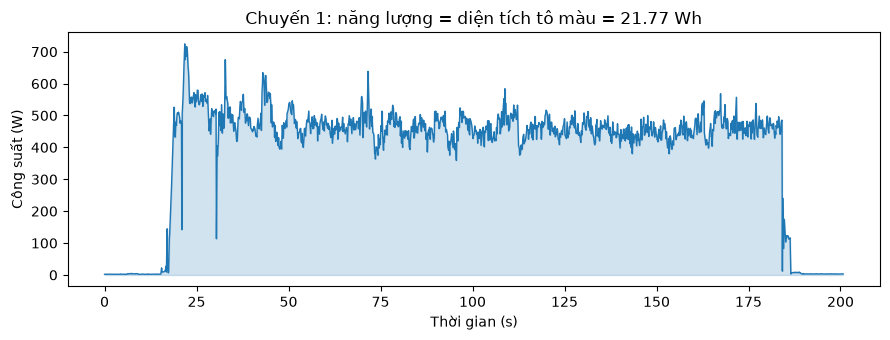

In [293]:
# Biểu đồ 1: công suất theo thời gian của chuyến 1
# Phần tô màu dưới đường chính là năng lượng (diện tích = công suất × thời gian)
f1 = flights[flights["flight"] == 1]

plt.figure(figsize=(9, 3.5))
plt.plot(f1["time"], f1["P"], color="tab:blue", linewidth=1)
plt.fill_between(f1["time"], f1["P"], color="tab:blue", alpha=0.2)
plt.xlabel("Thời gian (s)")
plt.ylabel("Công suất (W)")
plt.title(f"Chuyến 1: năng lượng = diện tích tô màu = {E_Wh[1]:.2f} Wh")
plt.tight_layout()
plt.savefig(FIGURES / "cong_suat_chuyen_1.png", dpi=150)
plt.show()

**Đọc biểu đồ:** khoảng 17 giây đầu drone nằm dưới đất, công suất gần 0. Lúc cất cánh công suất vọt lên khoảng 700 W (leo lên tốn nhất), sau đó bay hành trình ổn định khoảng 400–550 W, và về gần 0 khi hạ cánh (khoảng giây 185). Phần tô màu là năng lượng cả chuyến, 21,77 Wh.

### 4.3 So hình thang với Riemann

Cách đơn giản hơn là **tổng Riemann**: mỗi đoạn chỉ lấy công suất ở đầu đoạn, E_đoạn = P_trước × Δt. Nếu 2 cách ra gần bằng nhau thì kết quả không phụ thuộc vào cách tính, tức là đáng tin.

In [294]:
flights["E_doan_riemann"] = flights["P_truoc"] * flights["dt"]
E_riemann_Wh = flights.groupby("flight")["E_doan_riemann"].sum() / 3600

# Chỉ xét 192 chuyến giữ lại
lech_pct = ((E_Wh - E_riemann_Wh).abs() / E_Wh * 100).loc[giu["flight"]]
print("Chuyến 1 | hình thang:", round(E_Wh[1], 3), "Wh | Riemann:", round(E_riemann_Wh[1], 3), "Wh")
print("Độ lệch giữa 2 cách trên 192 chuyến (%):")
lech_pct.describe().round(3)

Chuyến 1 | hình thang: 21.766 Wh | Riemann: 21.762 Wh
Độ lệch giữa 2 cách trên 192 chuyến (%):


count    192.000
mean       0.051
std        0.045
min        0.000
25%        0.019
50%        0.040
75%        0.075
max        0.247
dtype: float64

**Kết luận:** chuyến 1 ra 21,766 Wh (hình thang) và 21,762 Wh (Riemann). Trên 192 chuyến, 2 cách lệch trung bình khoảng 0,05%, lớn nhất khoảng 0,25%. Vì máy ghi dày (khoảng 0,15 s một lần) nên cách tính gần như không ảnh hưởng. Nhóm dùng **hình thang** vì chính xác hơn (lấy trung bình 2 đầu đoạn).

### 4.4 Bảng năng lượng cho 192 chuyến

In [295]:
tom_tat = flights.groupby("flight").agg(
    thoi_gian_s=("time", lambda t: t.max() - t.min()),
    P_tb_W=("P", "mean"),
    P_max_W=("P", "max"),
)
tom_tat["E_Wh"] = E_Wh

nang_luong = giu.merge(tom_tat, left_on="flight", right_index=True)
print("Số chuyến:", len(nang_luong))
nang_luong["E_Wh"].describe().round(2)

Số chuyến: 192


count    192.00
mean      21.27
std        4.90
min       12.99
25%       17.62
50%       20.79
75%       24.53
max       37.75
Name: E_Wh, dtype: float64

In [296]:
# Chuyến tốn ít nhất và nhiều nhất
nang_luong.loc[[nang_luong["E_Wh"].idxmin(), nang_luong["E_Wh"].idxmax()],
               ["flight", "speed", "payload", "altitude", "route", "thoi_gian_s", "E_Wh"]]

,flight,speed,payload,altitude,route,thoi_gian_s,E_Wh
9,12,10.0,0.0,25,R1,116.21,12.991369
203,272,4.0,250.0,50,R6,428.29,37.747051


**Kết luận:** 192 chuyến tốn từ khoảng 13 Wh đến 37,7 Wh, trung bình khoảng 21,3 Wh. Tất cả đều dưới 40% dung lượng pin (≈ 100 Wh), hợp lý với các chuyến bay vài phút. Chuyến tốn nhiều nhất là 272 (4 m/s, 250 g, route R6), bay lâu nhất (khoảng 7 phút).

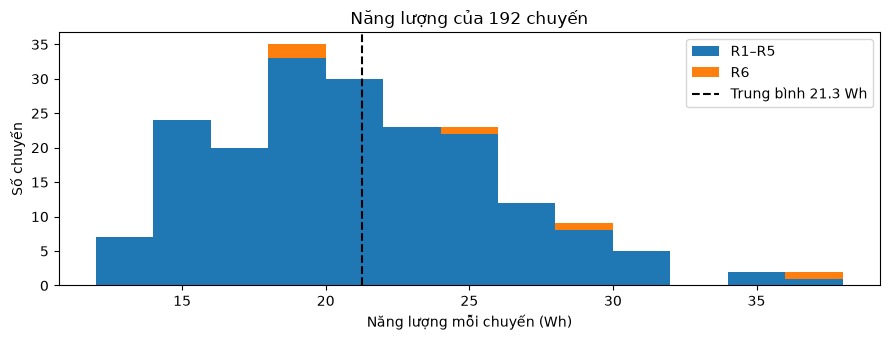

In [297]:
# Biểu đồ 2: phân bố năng lượng của 192 chuyến, tô riêng các chuyến R6
r6 = nang_luong[nang_luong["route"] == "R6"]["E_Wh"]
con_lai = nang_luong[nang_luong["route"] != "R6"]["E_Wh"]
bins = range(12, 40, 2)   # mỗi cột rộng 2 Wh

plt.figure(figsize=(9, 3.5))
plt.hist([con_lai, r6], bins=bins, stacked=True,
         color=["tab:blue", "tab:orange"], label=["R1–R5", "R6"])
plt.axvline(nang_luong["E_Wh"].mean(), color="black", linestyle="--",
            label=f"Trung bình {nang_luong['E_Wh'].mean():.1f} Wh")
plt.xlabel("Năng lượng mỗi chuyến (Wh)")
plt.ylabel("Số chuyến")
plt.title("Năng lượng của 192 chuyến")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES / "phan_bo_nang_luong.png", dpi=150)
plt.show()

**Đọc biểu đồ:** phần lớn các chuyến tốn 14–26 Wh, lệch về bên phải (có một số chuyến tốn nhiều, tới 37 Wh). Các chuyến R6 (màu cam) **không nổi bật** trong biểu đồ này, vì năng lượng còn phụ thuộc tốc độ, tải, độ cao. Chỉ khi so với R1 **cùng cài đặt** (mục 4.5) mới thấy R6 tốn hơn rõ ràng. Bài học: muốn thấy ảnh hưởng của một yếu tố thì phải so trong điều kiện giống nhau.

### 4.5 Kiểm điểm còn mở: route khác R1 có tốn năng lượng khác không?

Mục 3 để ngỏ câu hỏi về các route R2–R6 (README: khác R1 ở điểm xuất phát). So mỗi chuyến route khác với **trung bình các chuyến R1 cùng cài đặt** (cùng tốc độ, tải, độ cao):

In [298]:
# Năng lượng trung bình của R1 theo từng bộ cài đặt
r1 = nang_luong[nang_luong["route"] == "R1"]
tb_r1 = r1.groupby(["speed", "payload", "altitude"])["E_Wh"].mean().rename("E_R1_cung_cai_dat")

# Các chuyến route khác, ghép với trung bình R1 cùng cài đặt
khac = nang_luong[nang_luong["route"] != "R1"].join(tb_r1, on=["speed", "payload", "altitude"])
khac["chenh_pct"] = (khac["E_Wh"] / khac["E_R1_cung_cai_dat"] - 1) * 100
khac[["flight", "route", "speed", "payload", "altitude", "E_Wh", "E_R1_cung_cai_dat", "chenh_pct"]].round(1)

,flight,route,speed,payload,altitude,E_Wh,E_R1_cung_cai_dat,chenh_pct
0,1,R5,4.0,0.0,25,21.8,21.9,-0.7
1,2,R5,4.0,0.0,50,25.4,23.0,10.4
2,3,R5,6.0,0.0,25,17.1,16.3,5.0
3,4,R5,8.0,0.0,25,14.7,14.4,2.4
4,5,R2,4.0,0.0,25,19.0,21.9,-13.1
5,6,R3,4.0,0.0,25,20.1,21.9,-8.3
6,7,R4,4.0,0.0,25,21.5,21.9,-1.8
199,268,R6,6.0,500.0,25,28.7,19.6,46.4
200,269,R6,12.0,500.0,25,19.9,15.0,32.5
201,270,R6,10.0,250.0,75,24.0,20.4,17.7


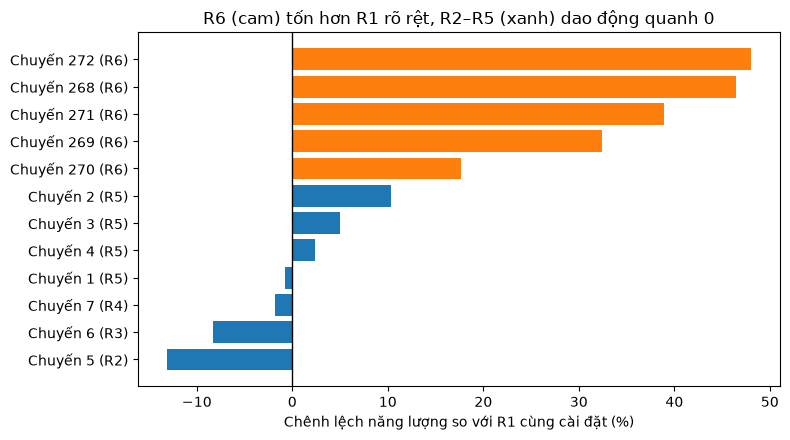

In [299]:
# Biểu đồ 3: mỗi chuyến route khác tốn hơn/kém R1 cùng cài đặt bao nhiêu %
khac_ve = khac.sort_values("chenh_pct")
nhan = [f"Chuyến {f} ({r})" for f, r in zip(khac_ve["flight"], khac_ve["route"])]
mau = ["tab:orange" if r == "R6" else "tab:blue" for r in khac_ve["route"]]

plt.figure(figsize=(8, 4.5))
plt.barh(nhan, khac_ve["chenh_pct"], color=mau)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Chênh lệch năng lượng so với R1 cùng cài đặt (%)")
plt.title("R6 (cam) tốn hơn R1 rõ rệt, R2–R5 (xanh) dao động quanh 0")
plt.tight_layout()
plt.savefig(FIGURES / "route_so_voi_R1.png", dpi=150)
plt.show()

**Kết luận:**
- R2, R3, R4, R5 (7 chuyến): chênh với R1 cùng cài đặt từ khoảng −13% đến +10%, nằm trong mức dao động bình thường giữa các chuyến.
- **R6 (5 chuyến): tốn hơn R1 cùng cài đặt từ khoảng 18% đến 48%**, cả 5 chuyến đều cao hơn. Có thể do đường bay R6 dài hơn (README: các route khác R1 ở điểm xuất phát).

**Quyết định: giữ 5 chuyến R6** và xử lý như một phát hiện có chủ đích, không giấu:
- Route không phải biến đầu vào, nên mô hình nhiều khả năng **đoán thiếu** năng lượng ở các chuyến R6. Với drone giao hàng, đoán thiếu là kiểu sai nguy hiểm (kế hoạch tưởng pin đủ mà thực tế không đủ), nên cần đo và báo cáo rõ.
- Giữ cột `route` trong bảng lưu ra (mục 5) để các bước sau tra lại được.
- **D3/D4 (phân tích lỗi):** kiểm xem các chuyến R6 có nằm trong nhóm sai số lớn nhất không; so kết quả mô hình khi có và không có R6 để đo mức ảnh hưởng.
- **Báo cáo cuối:** ghi là hạn chế, hướng cải thiện là thêm quãng đường bay (tính từ position_x, position_y) làm biến đầu vào.

Giữ R6 cũng giúp bộ dữ liệu thống nhất với 192 chuyến nhóm đã dùng huấn luyện mô hình.

## 5. Gom bảng và lưu

- [x] Bảng cuối có bao nhiêu chuyến? → 192 chuyến (mục 5.1)
- [x] Cột nào biết TRƯỚC khi bay, cột nào chỉ có SAU khi bay? → từ điển dữ liệu (mục 5.2)
- [x] Lưu `flight_level.csv` và `exclusion_log.csv` → mục 5.3

### 5.1 Bảng cuối: mỗi dòng một chuyến bay

**Vì sao chọn 11 cột này?** Cách chọn: xem các bước sau (EDA, mô hình, phân tích lỗi) cần gì, rồi giữ đúng những cột đó.

| Nhóm | Cột | Để làm gì |
|---|---|---|
| Định danh | `flight` | Biết dòng nào là chuyến nào, tra ngược lại telemetry được |
| **Đầu vào** | `speed`, `payload`, `altitude` | Câu hỏi nghiên cứu: "dự đoán từ tốc độ, tải, độ cao" → đúng 3 cột này |
| **Mục tiêu** | `E_Wh` | Cái mô hình phải dự đoán |
| Giải thích, tra lỗi | `route`, `date`, `local_time`, `thoi_gian_s`, `P_tb_W`, `P_max_W` | **Không** đưa vào mô hình. Dùng để giải thích kết quả (ví dụ vì sao bay nhanh lại tiết kiệm) và phân tích lỗi (ví dụ các chuyến R6) |

**Không giữ** 20 cột còn lại của `flights.csv` (gió, hướng quay, vận tốc, gia tốc...): chúng là số đo từng khoảng 0,15 giây **trong lúc bay**, vừa không phải một con số cho mỗi chuyến, vừa chỉ có **sau khi bay**, nên không dùng được cho mô hình lên kế hoạch trước chuyến bay. Nếu sau này cần thêm cột (ví dụ tốc độ gió trung bình, coi như dự báo thời tiết), chỉ cần thêm vào danh sách `cot_giu` rồi chạy lại notebook.

In [300]:
cot_giu = ["flight", "speed", "payload", "altitude",      # biến đầu vào (biết trước khi bay)
           "route", "date", "local_time",                  # thông tin để tra cứu
           "thoi_gian_s", "P_tb_W", "P_max_W",             # chỉ biết sau khi bay
           "E_Wh"]                                         # biến mục tiêu
flight_level = nang_luong[cot_giu].sort_values("flight").reset_index(drop=True)

print("Kích thước:", flight_level.shape)
print("Ô trống:", flight_level.isna().sum().sum())
print("Mã chuyến trùng:", flight_level["flight"].duplicated().sum())
flight_level.head()

Kích thước: (192, 11)
Ô trống: 0
Mã chuyến trùng: 0


,flight,speed,payload,altitude,route,date,local_time,thoi_gian_s,P_tb_W,P_max_W,E_Wh
0,1,4.0,0.0,25,R5,2019-04-07,10:13,200.7,390.047110,724.557377,21.765760
1,2,4.0,0.0,50,R5,2019-04-07,10:23,271.2,336.631861,820.169833,25.374148
2,3,6.0,0.0,25,R5,2019-04-07,10:33,180.1,341.261039,754.444448,17.090203
3,4,8.0,0.0,25,R5,2019-04-07,10:48,171.0,309.511243,765.562258,14.701160
4,5,4.0,0.0,25,R2,2019-04-07,11:05,217.0,316.418567,706.827986,19.048959


**Kết luận:** bảng cuối có **192 dòng × 11 cột**, mỗi dòng là một chuyến bay, không có ô trống, không có chuyến bị lặp.

### 5.2 Từ điển dữ liệu (data dictionary)

Chia cột theo **thời điểm biết được**. Mô hình dùng để lên kế hoạch **trước khi bay**, nên chỉ được dùng các cột biết trước. Nếu đưa cột chỉ có sau khi bay (ví dụ thời gian bay) vào mô hình thì gọi là **rò rỉ dữ liệu** (data leakage): mô hình trông rất giỏi nhưng ngoài thực tế không dùng được, vì lúc lên kế hoạch chưa có con số đó.

| Cột | Kiểu | Ý nghĩa | Đơn vị | Vai trò |
|---|---|---|---|---|
| `flight` | số nguyên | Mã chuyến bay | | Định danh |
| `speed` | số thực | Tốc độ ngang được lập trình khi bay hành trình | m/s | **Đầu vào** (biết trước) |
| `payload` | số thực | Khối lượng hàng chở | g | **Đầu vào** (biết trước) |
| `altitude` | số nguyên | Độ cao bay cài đặt trước | m | **Đầu vào** (biết trước) |
| `route` | chữ | Tên đường bay (R1–R6) | | Tra cứu, phân tích lỗi (không đưa vào mô hình) |
| `date` | chữ | Ngày bay | YYYY-MM-DD | Tra cứu |
| `local_time` | chữ | Giờ bắt đầu bay (giờ Pittsburgh) | HH:MM | Tra cứu |
| `thoi_gian_s` | số thực | Thời gian ghi dữ liệu của chuyến | s | Chỉ có **sau** khi bay, **không** dùng làm đầu vào |
| `P_tb_W` | số thực | Công suất trung bình cả chuyến | W | Chỉ có **sau** khi bay, **không** dùng làm đầu vào |
| `P_max_W` | số thực | Công suất lớn nhất | W | Chỉ có **sau** khi bay, **không** dùng làm đầu vào |
| `E_Wh` | số thực | Năng lượng tiêu thụ cả chuyến (quy tắc hình thang) | Wh | **Mục tiêu** (cần dự đoán) |

### 5.3 Lưu file

In [301]:
# Bảng một chuyến một dòng -> dùng cho EDA và mô hình
flight_level.to_csv(PROCESSED / "flight_level.csv", index=False)

# Sổ loại: chuyến nào bị loại, vì luật nào, bằng chứng gì
(ROOT / "reports").mkdir(exist_ok=True)
# utf-8-sig để mở bằng Excel không bị lỗi font tiếng Việt
so_loai.to_csv(ROOT / "reports" / "exclusion_log.csv", index=False, encoding="utf-8-sig")

print("Đã lưu:", PROCESSED / "flight_level.csv")
print("Đã lưu:", ROOT / "reports" / "exclusion_log.csv")

Đã lưu: C:\Users\Lenovo\IdeaProjects\DTA\data\processed\flight_level.csv
Đã lưu: C:\Users\Lenovo\IdeaProjects\DTA\reports\exclusion_log.csv


Kiểm tra: đọc lại file vừa lưu, phải ra đúng kích thước như trước khi lưu.

In [302]:
kiem = pd.read_csv(PROCESSED / "flight_level.csv")
print("flight_level.csv:", kiem.shape)
print("exclusion_log.csv:", pd.read_csv(ROOT / "reports" / "exclusion_log.csv").shape)

flight_level.csv: (192, 11)
exclusion_log.csv: (17, 3)


**Kết luận:** đã lưu `data/processed/flight_level.csv` (192 × 11) và `reports/exclusion_log.csv` (17 dòng: chuyến, luật, bằng chứng). Đọc lại ra đúng kích thước. Notebook 02 (EDA) và các notebook sau sẽ bắt đầu từ `flight_level.csv`, không cần đọc lại file telemetry 257 nghìn dòng.

## Ghi chú cho báo cáo

**Bước này tìm ra gì** (dùng cho phần *Cleaning process* và *Processed dataset* của D2):

1. **Dữ liệu gốc:** `parameters.csv` 209 × 7 (mỗi dòng một chuyến) và `flights.csv` 257.896 × 28 (telemetry, khoảng 0,15 s một dòng), nối bằng cột `flight`. Nguồn: CMU KiltHub, giấy phép CC BY 4.0.
2. **Chất lượng:** không có ô trống, không có dòng trùng. Khoảng ghi không đều (0,06–5,28 s), có 10 chỗ ngắt trên 1 s nhưng mỗi chỗ dưới khoảng 1% thời gian bay nên giữ lại. Dòng điện âm nhỏ (trung bình −0,06 A) là nhiễu cảm biến khi motor tắt. Cột `altitude` bị lưu dạng chữ do có giá trị `25-50-100-25`.
3. **Lọc theo câu hỏi nghiên cứu (3 cửa):** loại 17 chuyến, còn **192**. Luật 1: 13 chuyến không phải bay giao hàng (speed = 0). Luật 2: 2 chuyến đổi độ cao giữa chừng (278, 279). Luật 3: 1 chuyến tải 750 g ngoài phạm vi (76). Luật 4: 1 chuyến ghi dư sau hạ cánh (196, cảm biến không hỏng).
4. **Năng lượng:** P = V × I, cộng theo quy tắc hình thang với Δt thật, đổi sang Wh. Kiểm bằng tính tay, hàm numpy và tổng Riemann (lệch dưới 0,25%). 192 chuyến tốn 13,0–37,7 Wh, trung bình 21,3 Wh.
5. **Hạn chế đã biết:** 5 chuyến route R6 tốn hơn R1 cùng cài đặt từ 18% đến 48%. Giữ lại, sẽ phân tích ở phần lỗi mô hình (D3/D4).

**Số liệu đưa vào báo cáo:** 209 → 192 chuyến; 17 chuyến bị loại theo 4 luật; năng lượng trung bình 21,3 Wh (độ lệch chuẩn 4,9 Wh).

**Đầu ra:** `data/processed/flight_level.csv`, `reports/exclusion_log.csv`, các hình trong `reports/figures/`.